# Monthly Global Predictor

Principal Component Analysis (PCA) of the monthly ERA5 **sea surface temperature (SST)** and
**mean sea level pressure (MSL)** fields between 60°S and 60°N (1950 onwards), and relationship of the
resulting principal components (PCs) with the main climate indices.

**Workflow**

1. **Predictors**: load ERA5 SST and MSL, reduce the domain and resolution, mask land and remove months
   with unrealistic values.
2. **Anomalies**: remove a quadratic (parabola) trend and the mean seasonal cycle at every grid point.
3. **Standardization + latitude weighting**: each grid point is standardized (zero mean, unit variance)
   so SST and MSL contribute equally, and multiplied by cos(latitude) so each point counts according
   to its area.
4. **PCA** of the combined SST + MSL field, keeping 98% of the variance: explained variance, EOF maps and
   PCs.
5. **Climate indices**: for each index, correlation with each PC and reconstruction of the index from the
   PCs with a multiple linear regression; summary of all the indices at the end.

Each section starts with a short description of what is computed and what the figures show.

Outputs (folder `outputs/`): filtered fields, PCA predictor, PCA model and a NetCDF with the PCs and the
climate indices (used by `02_PCs_analysis.ipynb`). The indices are read from `inputs/climate_indices.nc`,
updated with `00b_update_climate_indices.ipynb`.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

from bluemath_tk.datamining.pca import PCA

from utils.preprocessing import (apply_land_mask, remove_anomalous_months, detrend_dataset,
                                 deseasonalize, standardize_lat_weighted)
from utils.plotting import (plot_global_maps, plot_spatial_mean_trend,
                            plot_preprocessing_steps, plot_eofs_scaled, plot_explained_variance)
from utils.climate_indices import (analyze_index, save_pcs_indices, plot_regression_summary,
                                   plot_correlation_summary)
from utils.pcs_analysis import pc_index_correlation, top_pcs_table, plot_pc_index_heatmap

In [2]:
p_era5 = '/lustre/geocean/WORK/users/cagigall/personal/Projects/Projects_Global_Weather_Types/AWT_Global/notebooks/'

p_sst = os.path.join(p_era5, 'ERA5_global_sst_monthly_1degree.nc')
p_msl = os.path.join(p_era5, 'ERA5_global_msl_monthly_1degree.nc')

p_indices = os.path.join('inputs', 'climate_indices.nc')  # updated with 00b_update_climate_indices.ipynb
DETREND_DEG = 2  # degree of the trend removed from the indices (2 = same parabola as the fields, None = no detrend)

p_out = 'outputs'
if not os.path.exists(p_out):
    os.makedirs(p_out)
p_fields = os.path.join(p_out, 'sst_mslp_monthly_1day_lat_corr.nc')  # masked + filtered fields (before detrend)
p_predictor = os.path.join(p_out, 'sst_detrend_monthly_1day_lat_corr.nc')
p_pca_model = os.path.join(p_out, 'pca_model_SST_MSLP_ALL_lat_corr.pkl')
p_pcs_indices = os.path.join(p_out, 'pca_SST_MSLP_ALL_lat_corr_climate_indexes.nc')

# **Predictors**
## Load SST and MSL - ERA5
Monthly ERA5 SST [°C] and MSL [hPa] on a 0.5° grid, from 1950 onwards. Missing MSL values are filled with
1024 hPa (they are masked later, as only ocean points are used).

Maps: mean SST (left) and mean MSL (right) over the whole period.

In [3]:
xds = xr.load_dataset(p_sst).sortby('latitude')
xds['msl'] = xr.load_dataset(p_msl).sortby('latitude').msl.fillna(1024)
xds = xds.sel(time=slice('1950', None))
xds

<xarray.Dataset> Size: 2GB
Dimensions:    (time: 858, longitude: 720, latitude: 361)
Coordinates:
  * time       (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2024-05-01
  * longitude  (longitude) float32 3kB 0.125 0.625 1.125 ... 358.6 359.1 359.6
  * latitude   (latitude) float32 1kB -90.0 -89.62 -89.12 ... 88.88 89.38 89.88
Data variables:
    sst        (time, latitude, longitude) float32 892MB nan nan ... -1.692
    msl        (time, latitude, longitude) float32 892MB 1.008e+03 ... 1.018e+03

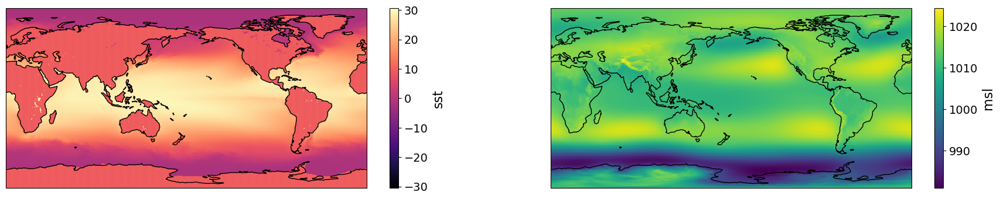

In [4]:
plot_global_maps([xds.sst.mean('time'), xds.msl.mean('time')], cmaps=['magma', 'viridis']);

## Domain, resolution and land mask
- Domain limited to 60°S–60°N (sea ice and very sparse data at higher latitudes).
- Resolution reduced from 0.5° to 2° (average of 4 × 4 blocks) to make the PCA lighter.
- The last month is removed (usually incomplete).
- Land points are masked with the Natural Earth 1:110m land polygons, so both SST and MSL are only
  used over the ocean.

Map: mean SST after these steps (land points masked, in white).

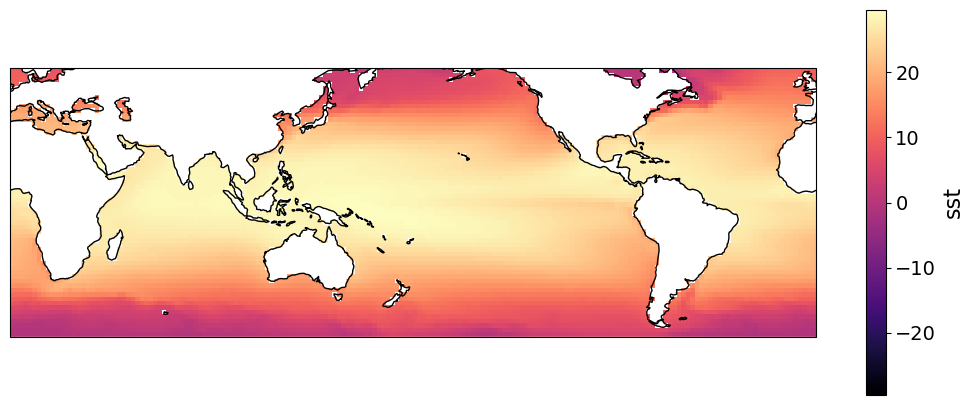

In [5]:
xds = xds.sel(latitude=slice(-60, 60))
xds = xds.coarsen(longitude=4, latitude=4, boundary='pad').mean()
xds = xds.isel(time=slice(0, -1))  # drop last (incomplete) month

xds = apply_land_mask(xds)
plot_global_maps([xds.sst.mean('time')], figsize=(13, 5));

## Remove anomalous months
Months whose spatial mean SST (< 18 °C) or MSL (< 1007 hPa) is unrealistic are removed
(Dec 1976, Jan 1988, May 2005, Dec 2013).

Figure: spatial mean of SST (top) and MSL (bottom) over the ocean for the remaining months (black), with
the quadratic trend (orange) that is removed in the next step. The filtered fields are saved to
`outputs/`.

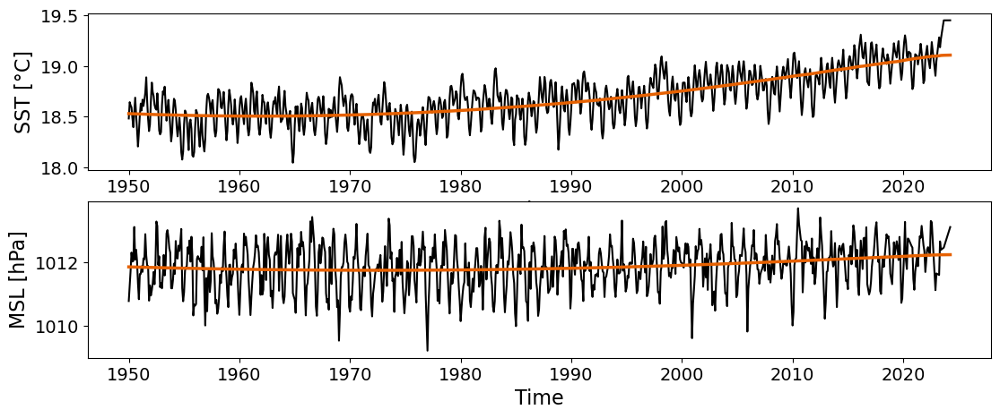

In [6]:
xds, means = remove_anomalous_months(xds, sst_min=18, msl_min=1007)
plot_spatial_mean_trend(means);

xds.to_netcdf(p_fields)

## Detrend (parabola) + deseasonalize
At every grid point:
1. **Detrend**: a 2nd-order polynomial (parabola) fitted in time is removed, keeping the initial value
   so the fields stay in physical units. A parabola captures the accelerating warming better than a
   linear trend.
2. **Deseasonalize**: the monthly climatology (mean of each calendar month) is removed and the overall
   mean added back.

The resulting anomalies keep the variability that is not explained by the trend or by the mean annual
cycle (month-to-month, interannual and decadal), which is what the PCA should capture.

Figures: the three steps for SST (top) and MSL (bottom): original (purple, transparent), detrended
(orange) and detrended + deseasonalized (green).
- First figure: a single grid point (160.9°E, 28.9°S, Tasman Sea), where the annual cycle is large.
- Second figure: spatial mean over the ocean.

After detrending, the series no longer drift in time; after deseasonalizing, the annual cycle disappears
and only the anomalies around the mean remain.

In [7]:
xds_detrended = detrend_dataset(xds, variables=['sst', 'msl'], deg=2)
xds_anomalies = deseasonalize(xds_detrended)

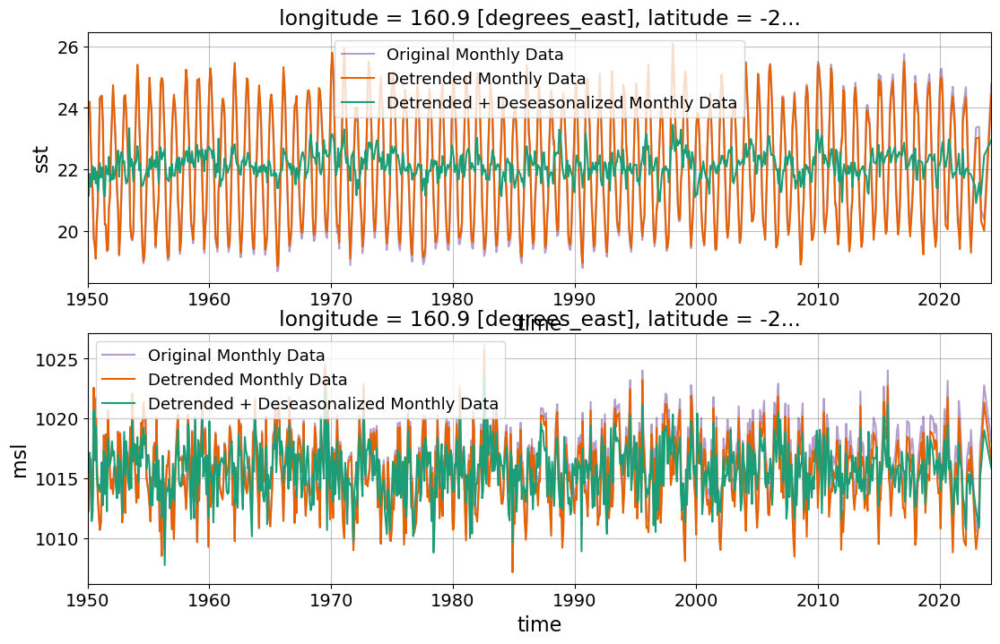

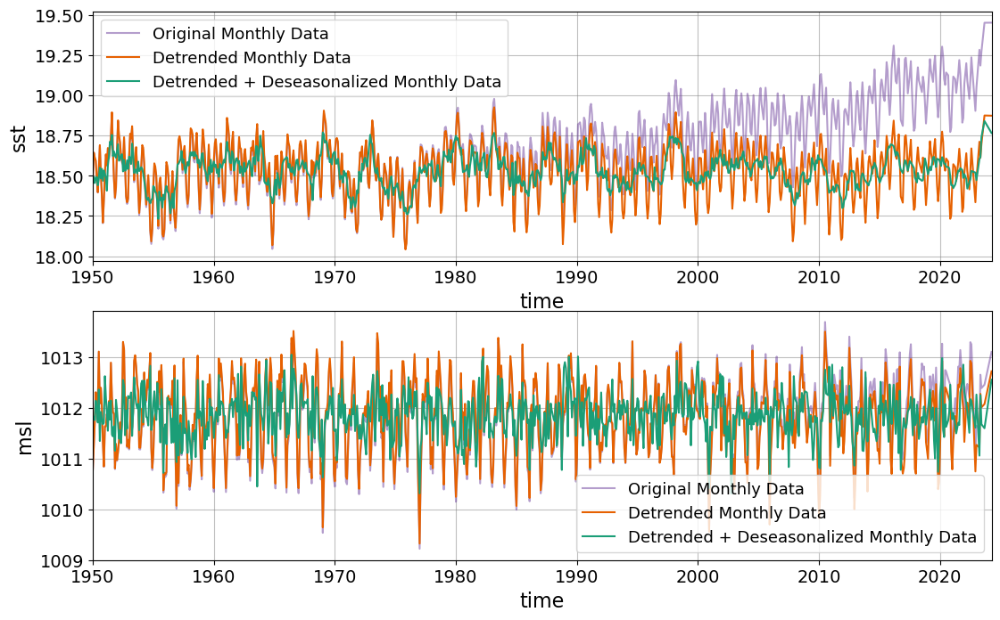

In [8]:
steps = {
    'Original': xds,
    'Detrended': xds_detrended,
    'Detrended + Deseasonalized': xds_anomalies,
}
plot_preprocessing_steps(steps, point=(80, 15));   # grid point
plot_preprocessing_steps(steps, point=None);       # global mean

## Predictor: standardization + latitude correction
The anomalies are stored as `sst_detrend` / `msl_detrend` and longitudes are converted to 0–360.

First figure (check of the anomalies): time mean of the SST anomalies (left; equal to the mean SST field,
since the overall mean was added back) and MSL anomalies of the first month (right).

Second figure: temporal standard deviation of the SST [°C] and MSL [hPa] anomalies. SST variability is
largest in the eastern equatorial Pacific (ENSO) and in the western boundary currents; MSL variability
grows towards mid-high latitudes (storm tracks). The two variables are very different in magnitude and in
space: without standardization, MSL (hPa) and the regions with the largest variance would dominate the
PCA.

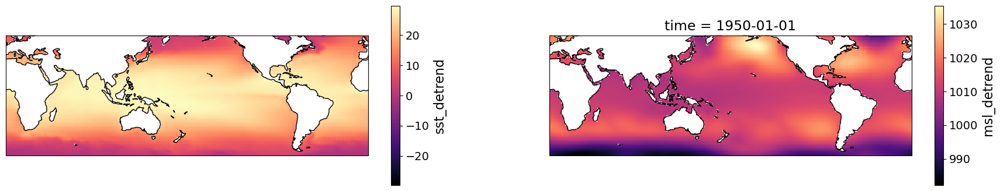

In [9]:
xds_pred = xr.Dataset({
    'sst_detrend': xds_anomalies.sst,
    'msl_detrend': xds_anomalies.msl,
}).transpose('time', 'latitude', 'longitude').reset_coords(drop=True)

lon = xds_pred.longitude.values
xds_pred = xds_pred.assign_coords(longitude=np.where(lon <= 0, lon + 360, lon))

plot_global_maps([xds_pred.sst_detrend.mean('time'), xds_pred.msl_detrend.isel(time=0)]);

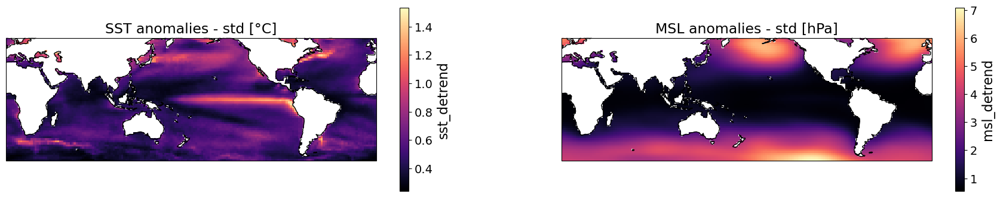

In [10]:
plot_global_maps([xds_pred.sst_detrend.std('time'), xds_pred.msl_detrend.std('time')],
                 cmaps=['magma', 'magma'],
                 titles=['SST anomalies - std [°C]', 'MSL anomalies - std [hPa]']);

Each grid point is standardized in time (zero mean, unit variance) and multiplied by **cos(latitude)**,
so that the contribution of each point to the total variance is proportional to its area (grid cells
shrink towards the poles).

Maps: first month of the final predictor (dimensionless), which is saved to `outputs/`.

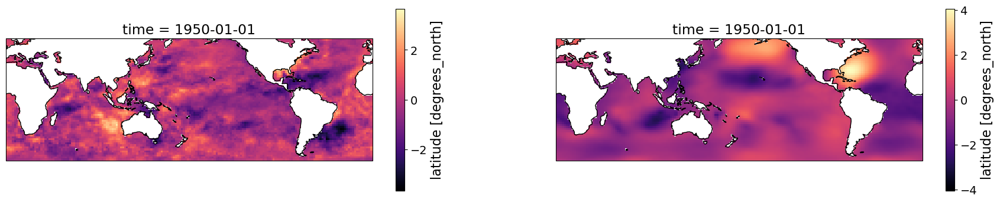

In [11]:
for var in ['sst_detrend', 'msl_detrend']:
    xds_pred[var] = standardize_lat_weighted(xds_pred[var])

plot_global_maps([xds_pred.sst_detrend.isel(time=0), xds_pred.msl_detrend.isel(time=0)]);

xds_pred.to_netcdf(p_predictor)

# **PCA**
PCA of the combined SST + MSL predictor (both variables stacked over all ocean grid points). No additional
scaling is applied because the data are already standardized and latitude-weighted. The number of
components retained explains 98% of the variance.

- **EOFs** (empirical orthogonal functions): spatial patterns of each mode. Each EOF covers SST and MSL
  together, so the SST map and the MSL map of mode *k* are two parts of the same pattern.
- **PCs**: time series of the amplitude of each mode (how strongly, and with which sign, the EOF pattern
  appears each month).

In [12]:
pca = PCA(n_components=.98)
pca._exclude_attributes = []

# No scaling: data are already detrended, deseasonalized, standardized and latitude-weighted
pca.fit_transform(
    data=xds_pred,
    vars_to_stack=['sst_detrend', 'msl_detrend'],
    coords_to_stack=['latitude', 'longitude'],
    pca_dim_for_rows='time',
    scale_data=False,
)
pca.save_model(p_pca_model)

2026-11-17 13:36:46,455 - PCA - WARNING - Using 7872 out of 10800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-11-17 13:36:46,471 - PCA - WARNING - Using 7872 out of 10800 available variables 
If this is originated by using few times, please check 'nan_threshold_to_drop' parameter in fit method
2026-11-17 13:36:46,491 - PCA - WARNING - Data is not standarized
2026-11-17 13:36:47,899 - PCA - WARNING - Attribute _data is an xarray Dataset / Dataarray and will be pickled!
2026-11-17 13:36:47,900 - PCA - WARNING - Attribute _window_processed_data is an xarray Dataset / Dataarray and will be pickled!
2026-11-17 13:36:47,900 - PCA - WARNING - Attribute pcs is an xarray Dataset / Dataarray and will be pickled!


### Explained variance
Bars: percentage of the variance of the predictor explained by each of the first 100 PCs. Black line
(right axis): cumulative explained variance; the dashed lines mark the number of PCs needed to reach 50%,
70% and 90%.

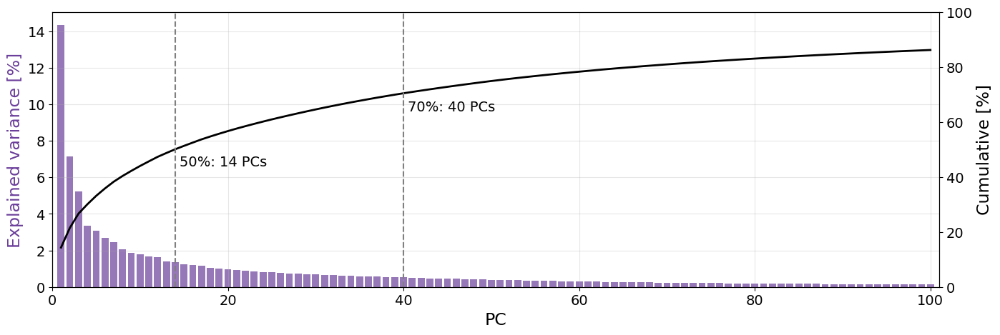

In [13]:
plot_explained_variance(pca.explained_variance_ratio, n_show=100);

### EOFs and PCs
Default bluemath plots, in the standardized and latitude-weighted units of the predictor:
1. SST part of the first 9 EOFs.
2. MSL part of the same 9 EOFs.
3. Time series of the first 9 PCs.

The sign of each mode is arbitrary: an EOF and its PC can change sign together without changing the
reconstructed field.

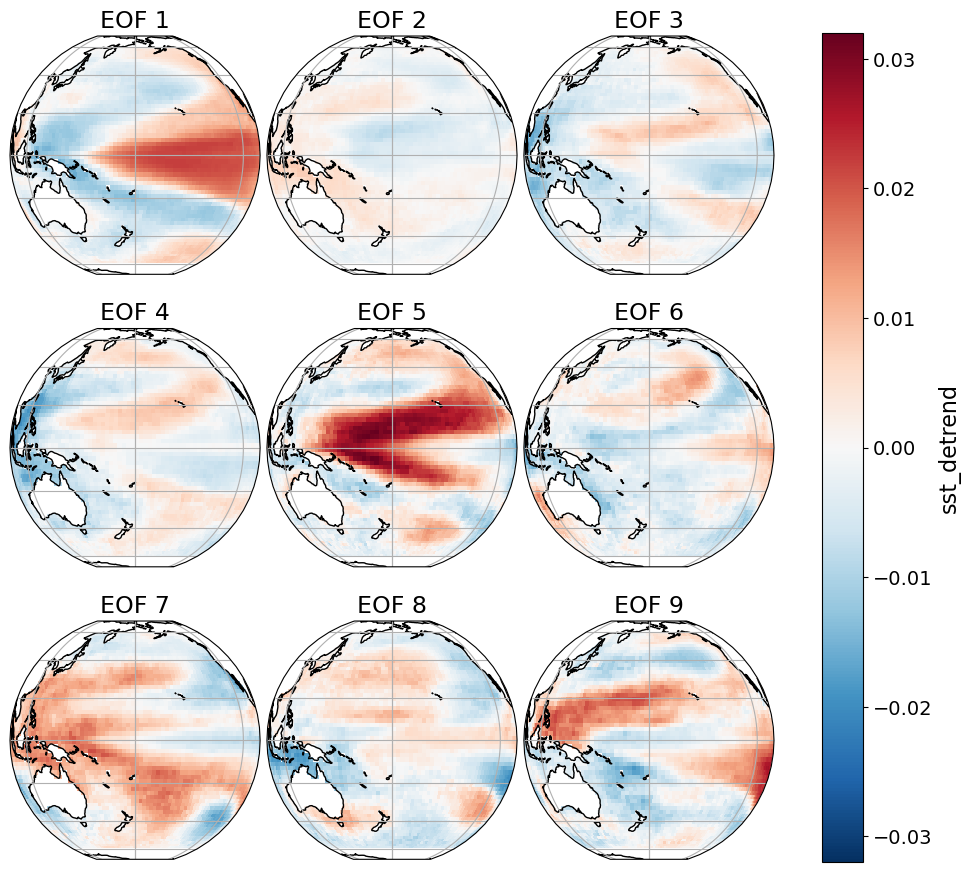

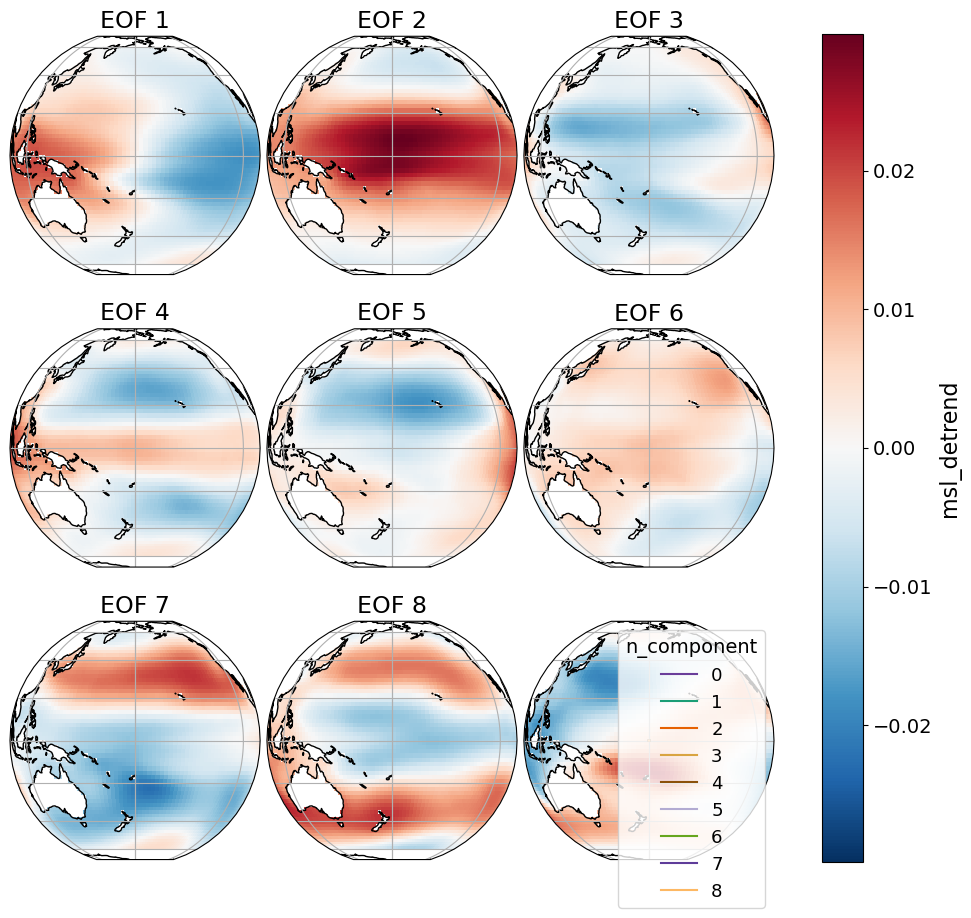

In [14]:
pca.plot_eofs(vars_to_plot=['sst_detrend'], num_eofs=9, map_center=(180, 0))
pca.plot_eofs(vars_to_plot=['msl_detrend'], num_eofs=9, map_center=(180, 0))
pca.plot_pcs(num_pcs=9)

### EOFs scaled by their PC
First 10 EOFs multiplied by the standard deviation of their PC, i.e. the typical anomaly associated with a
one-standard-deviation event of each mode (Mollweide projection centred on the Pacific). The title gives
the variance explained by each mode.

- First figure: SST part (orange: positive, purple: negative).
- Second figure: MSL part (green: positive, purple: negative).

The values are in the units of the predictor (standardized and multiplied by cos(latitude)), not in °C or
hPa, because each grid point was standardized before the PCA.

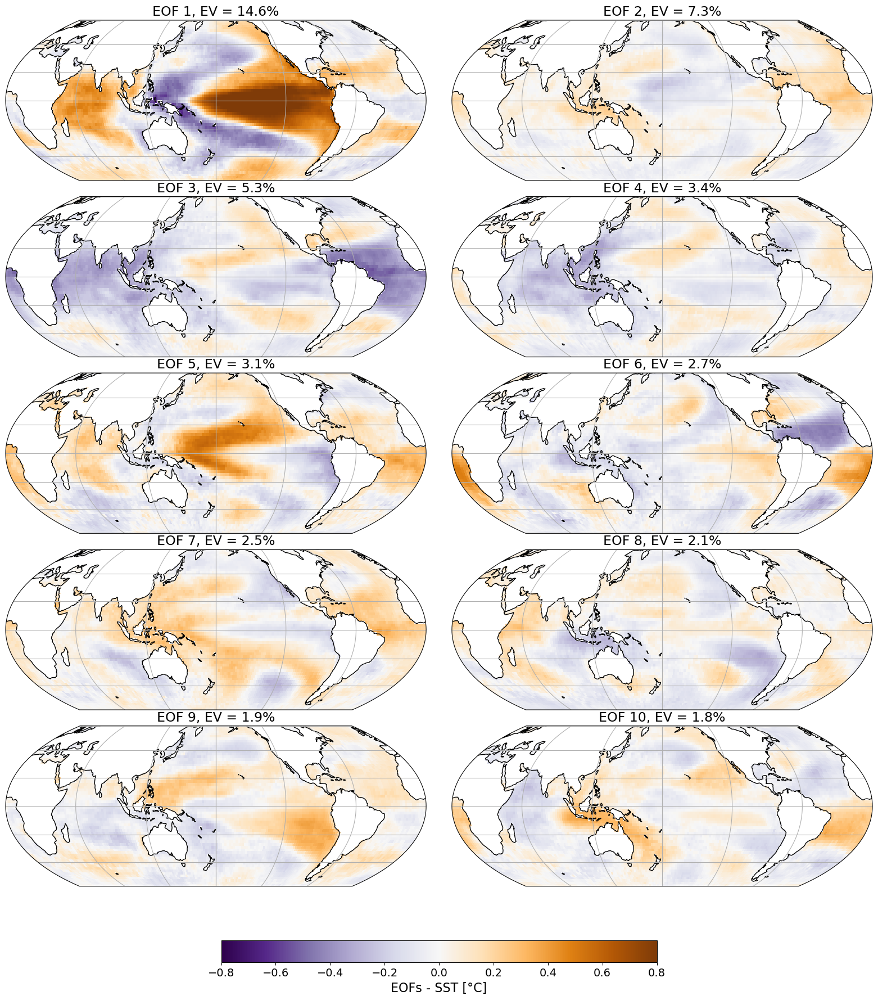

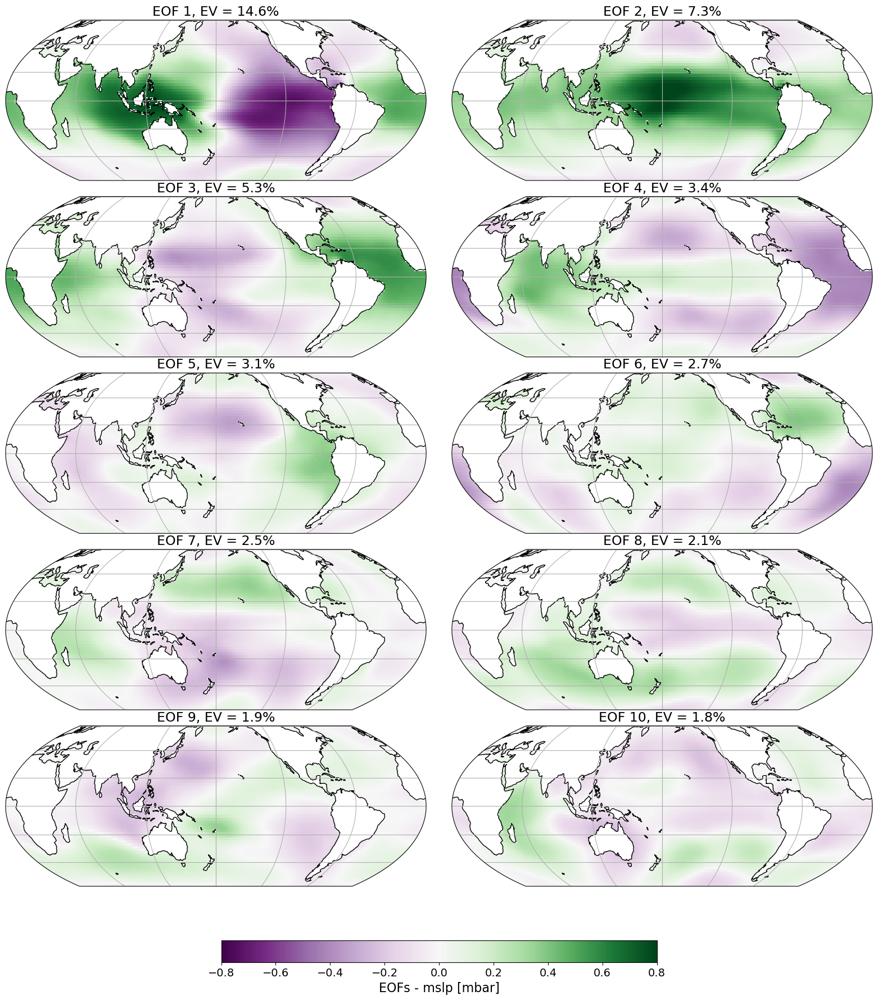

In [15]:
plot_eofs_scaled(pca, 'sst_detrend', num_eofs=10, cmap='PuOr_r', cbar_label='EOFs - SST [°C]');
plot_eofs_scaled(pca, 'msl_detrend', num_eofs=10, cmap='PRGn', cbar_label='EOFs - mslp [mbar]');

# **Climate indices**
Each index is compared with the first 100 PCs over the months where the index is available. Before
the comparison, the index is **detrended** over those months with the same quadratic trend removed from
the SST and MSL fields (`DETREND_DEG` in the paths cell; `None` keeps the published index),
since the PCs cannot reproduce a long-term trend. For each index, `analyze_index` produces:

1. **Index time series** as published (grey, with its trend), with the months above the upper
   threshold in orange and below the lower threshold in purple (`plot_thr` in `utils/climate_indices.py`, `INDICES`).
2. **Correlation with each PC**: Pearson correlation of the detrended index with each of the 100 PCs
   (stars, orange: positive, purple: negative).
3. **Most correlated PCs** (two figures): time series of the PCs with a correlation above the positive
   threshold and below the negative threshold (`corr_thr` in `INDICES`), in colour, together with the
   index (grey, right axis). The legend gives the correlation of each PC.
4. **Multiple linear regression**: observed index (grey) and index reconstructed from all the PCs (orange,
   right axis); the title gives the correlation between both. This correlation is computed in-sample, so
   it includes some overfitting (see `02_PCs_analysis.ipynb` for cross-validated values).

The indices are read from `inputs/climate_indices.nc` (updated with `00b_update_climate_indices.ipynb`).

In [16]:
n_pcs = 100
exp_variance = pca.explained_variance_ratio * 100
print(f'Explained variance with {n_pcs} PCs: {np.sum(exp_variance[:n_pcs]):.2f}%')

pcs = xr.DataArray(
    pca.pcs.PCs.values[:, :n_pcs],
    dims=('time', 'n_pcs'),
    coords={'time': xds_pred.time.values, 'n_pcs': np.arange(n_pcs)},
)
RESULTS = {}

Explained variance with 100 PCs: 86.17%


## NAO
**North Atlantic Oscillation** (NOAA CPC): pressure dipole between the Icelandic Low and the Azores High. It controls the strength and position of the North Atlantic jet stream and storm track, and is strongest in winter.

Multiple R  = 0.787
R^2         = 0.619
Intercept   = -0.003


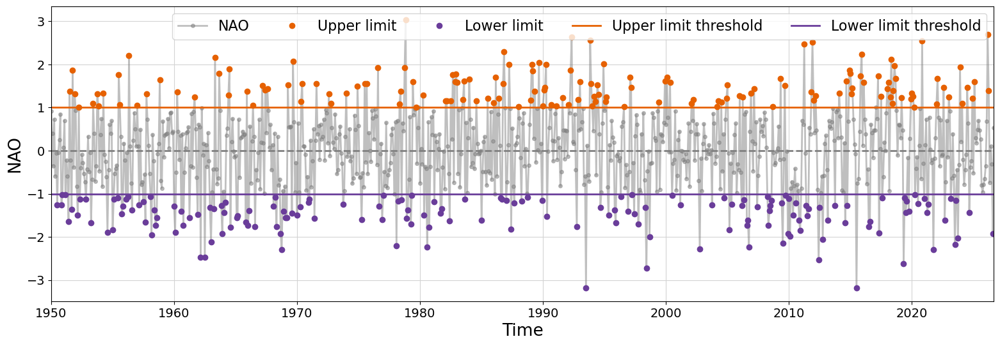

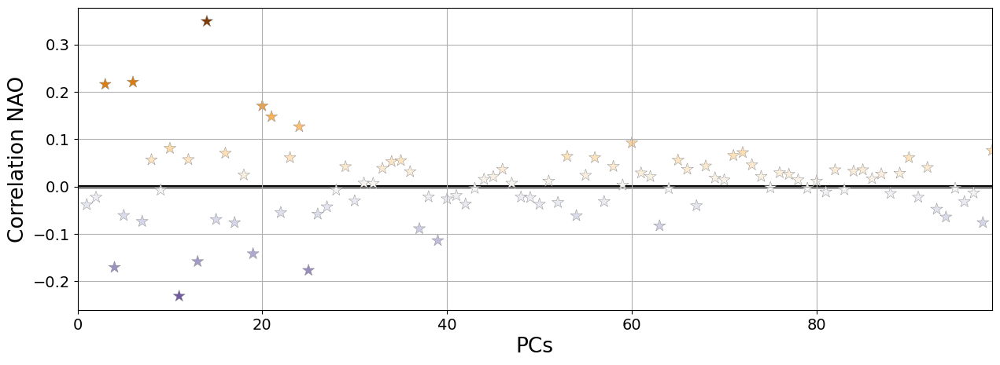

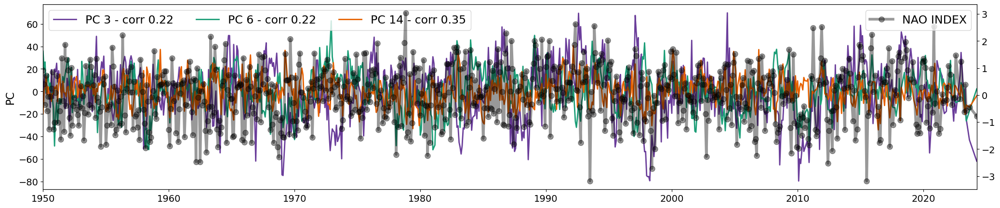

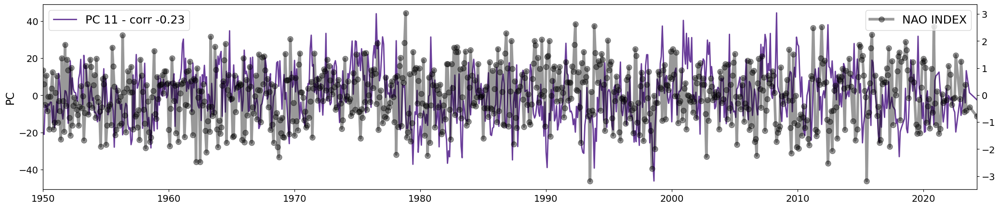

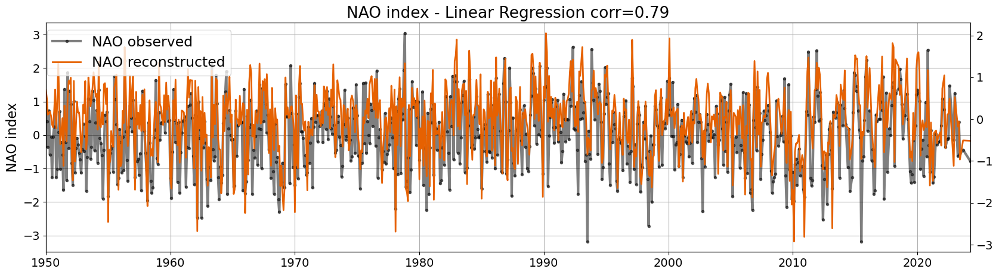

In [17]:
RESULTS['NAO'] = analyze_index('NAO', pcs, p_indices, detrend_deg=DETREND_DEG)

## AO
**Arctic Oscillation** (NOAA CPC): leading mode of extratropical Northern Hemisphere pressure variability, an annular pattern with opposite anomalies over the Arctic and mid-latitudes. Closely related to the NAO.

Multiple R  = 0.903
R^2         = 0.815
Intercept   = -0.098


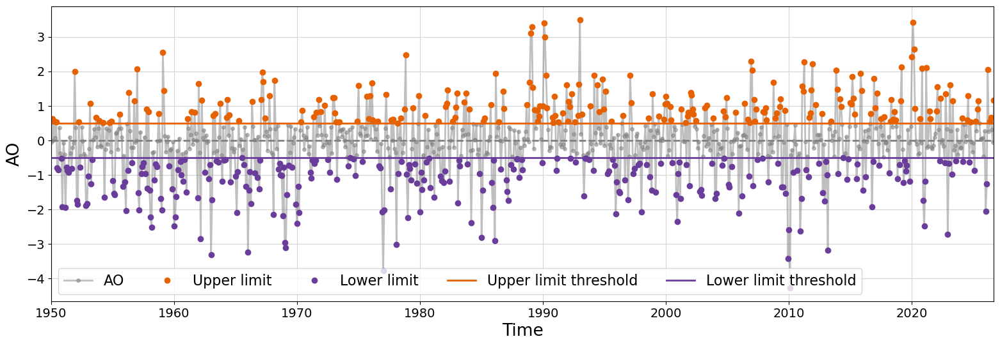

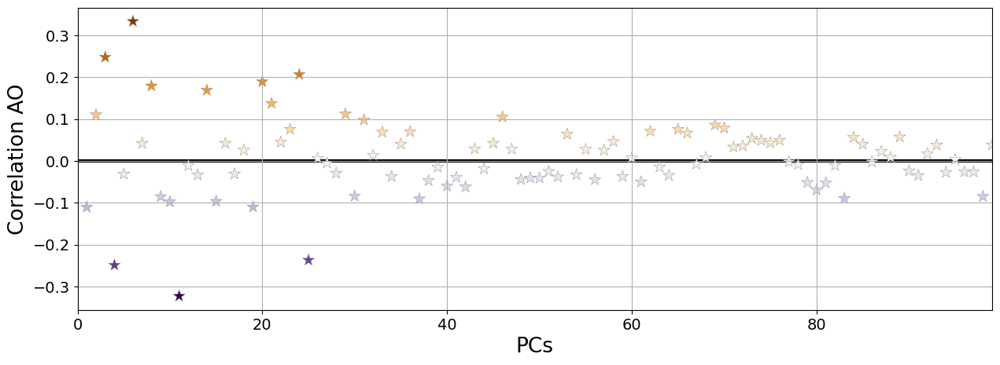

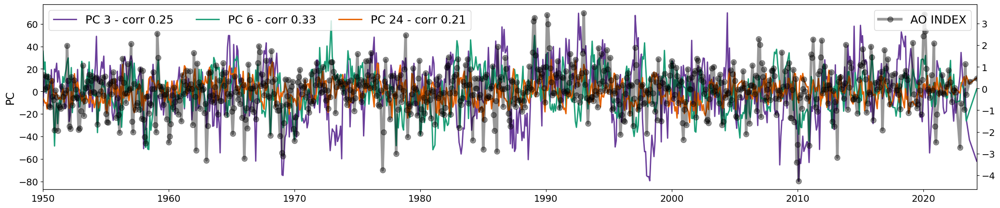

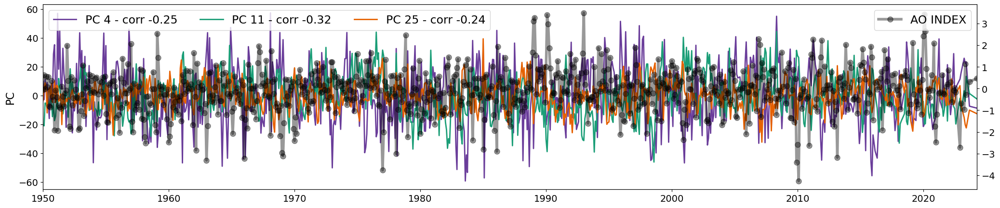

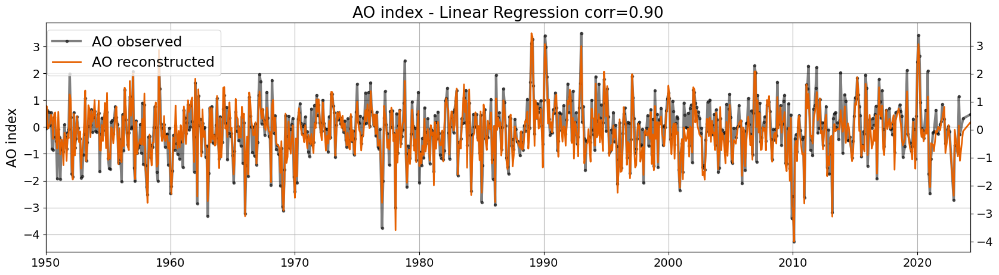

In [18]:
RESULTS['AO'] = analyze_index('AO', pcs, p_indices, detrend_deg=DETREND_DEG)

## AMO
**Atlantic Multidecadal Oscillation** (NOAA NCEI, ERSSTv5): North Atlantic (0–60°N) SST anomaly. This version is not detrended (it includes the long-term warming); like the other indices, it is detrended here before comparing it with the PCs.

Multiple R  = 0.515
R^2         = 0.265
Intercept   = 0.124


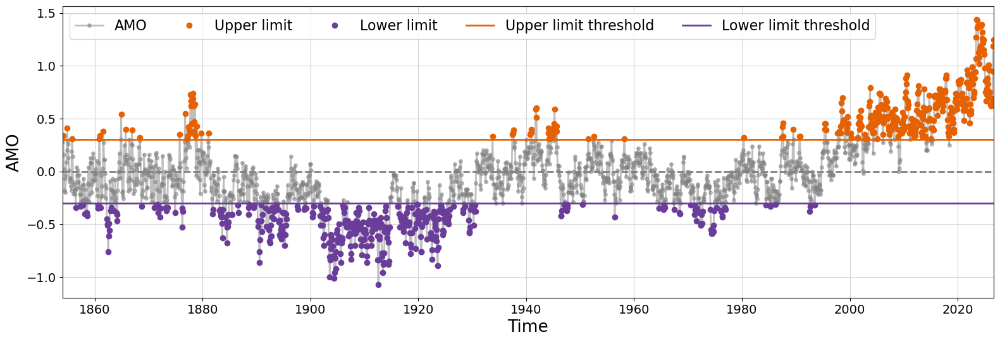

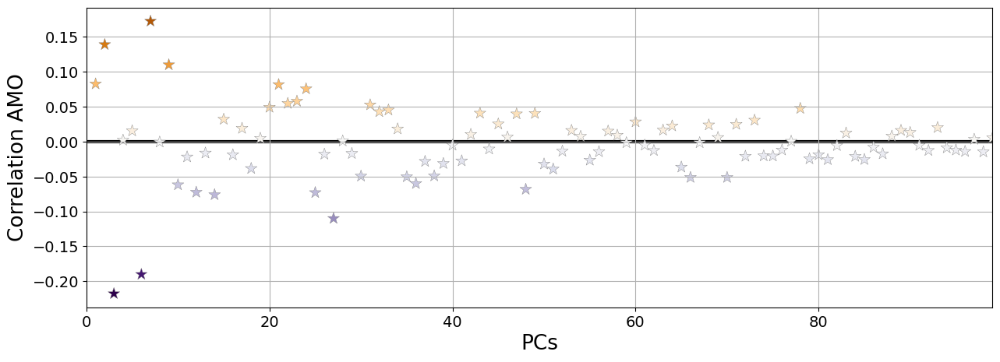

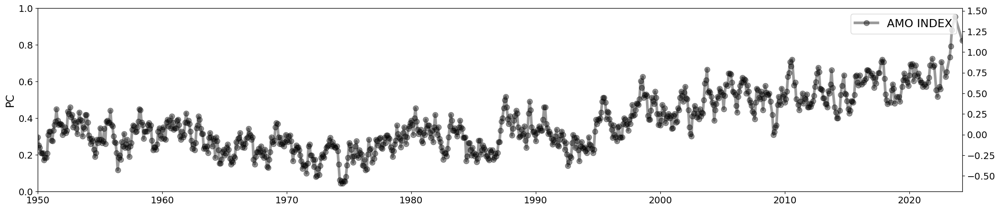

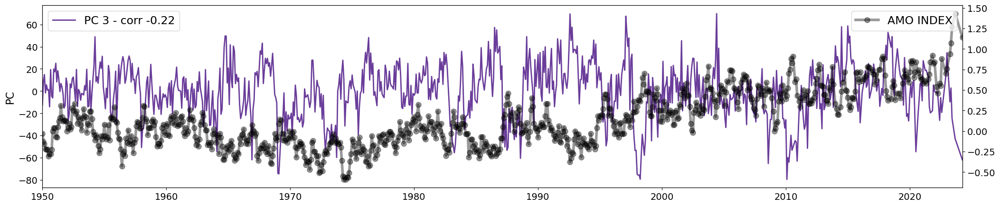

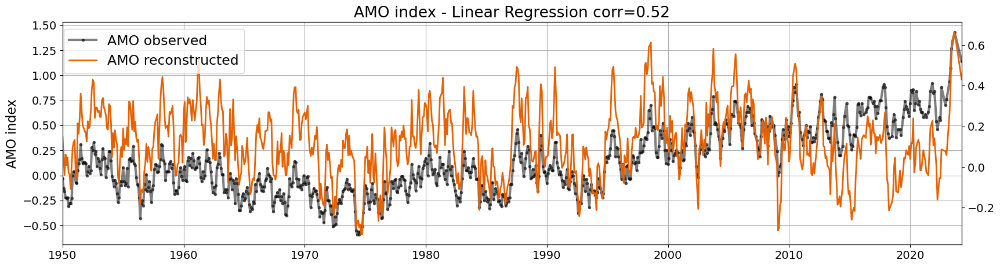

In [19]:
RESULTS['AMO'] = analyze_index('AMO', pcs, p_indices, detrend_deg=DETREND_DEG)

## SCAND
**Scandinavia pattern** (NOAA CPC): circulation centre over Scandinavia with weaker centres of opposite sign over western Europe and Mongolia; positive phase associated with blocking anticyclones over Scandinavia.

Multiple R  = 0.688
R^2         = 0.473
Intercept   = 0.113


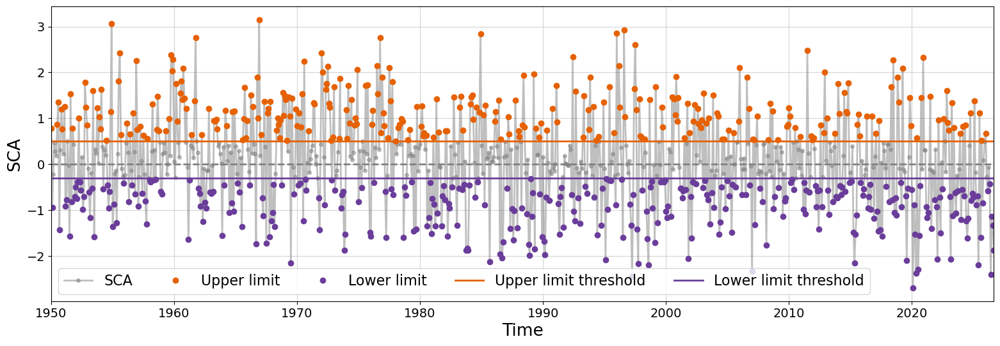

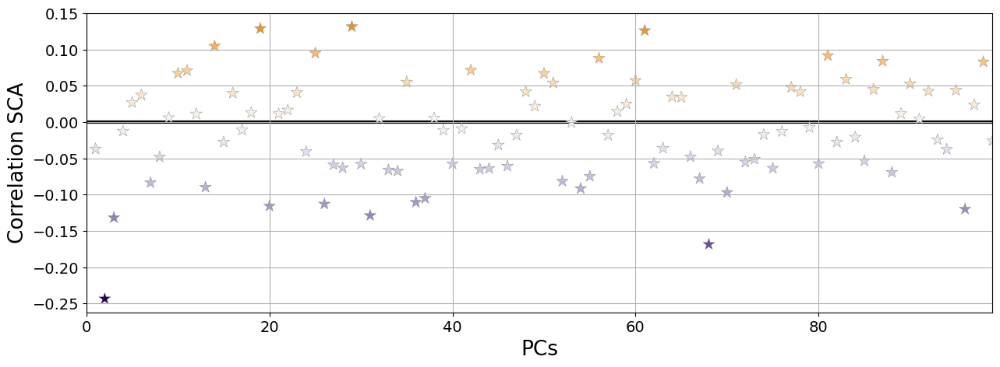

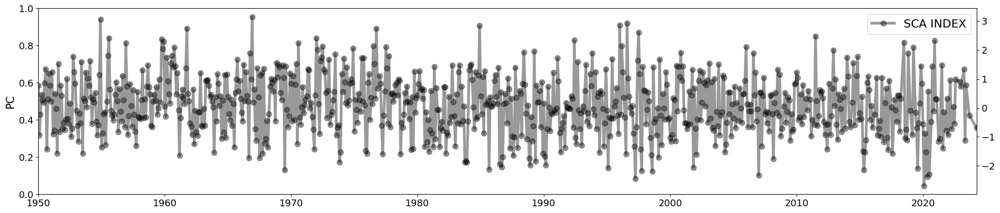

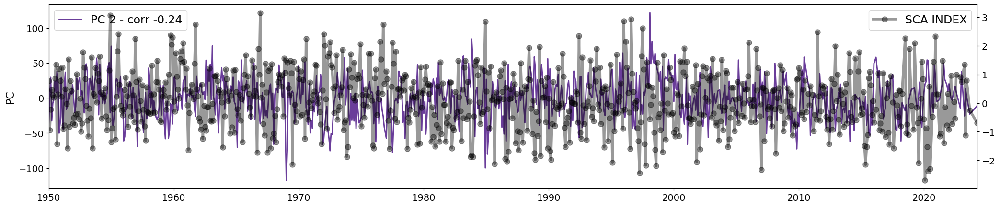

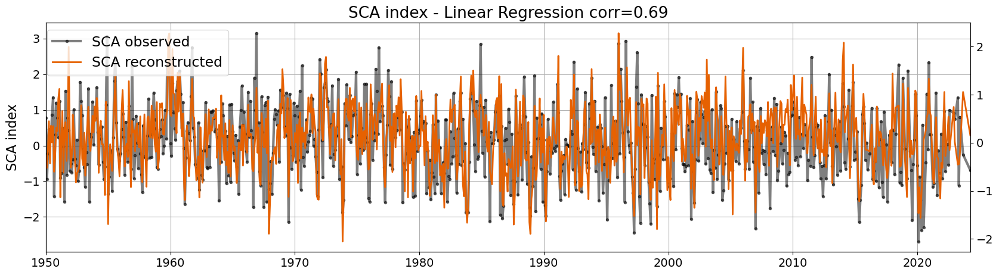

In [20]:
RESULTS['SCA'] = analyze_index('SCA', pcs, p_indices, detrend_deg=DETREND_DEG)

## NIÑO 3.4
**Niño 3.4** (NOAA NCEI, ERSSTv5): SST in the central equatorial Pacific (5°N–5°S, 170°W–120°W), expressed as anomaly with respect to 1991–2020 and smoothed with a 3-month running mean. Main oceanic index of ENSO (positive = El Niño).

Multiple R  = 0.866
R^2         = 0.749
Intercept   = -0.192


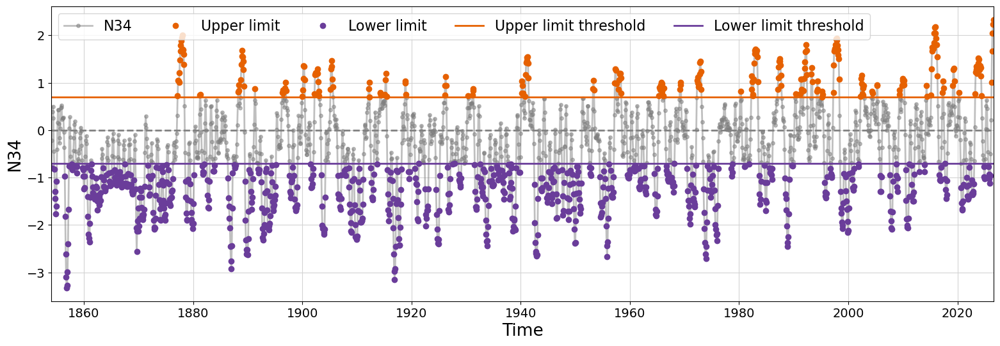

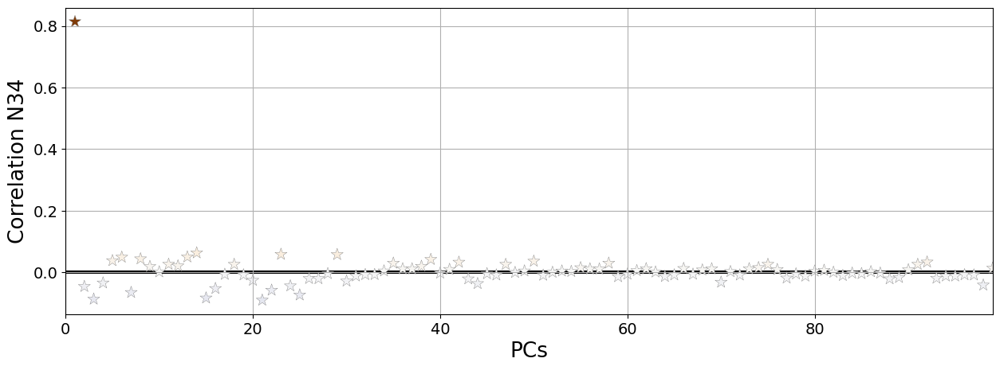

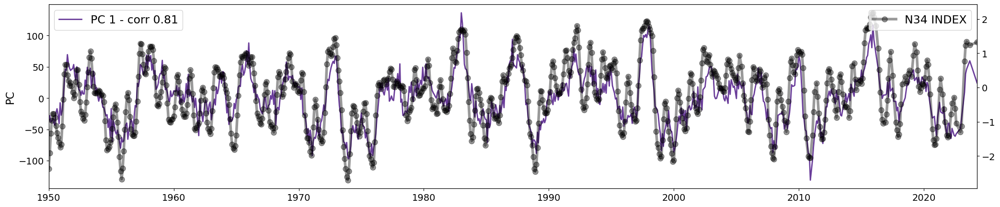

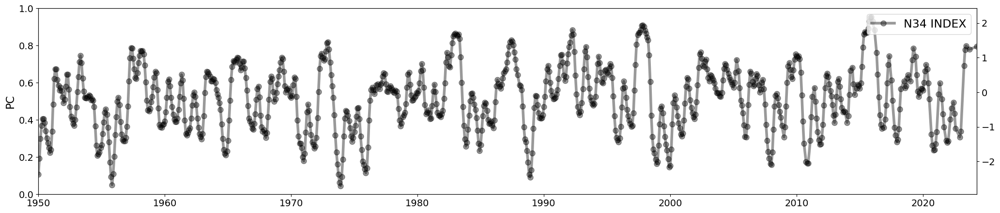

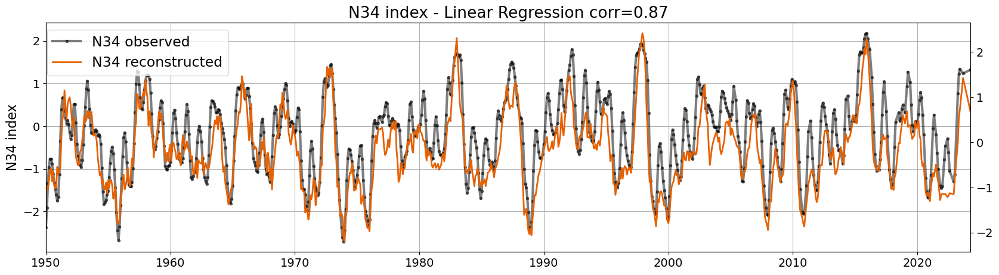

In [21]:
RESULTS['N34'] = analyze_index('N34', pcs, p_indices, detrend_deg=DETREND_DEG)

## OLR
**Outgoing Longwave Radiation** (NOAA CPC, standardized) over the equatorial Pacific (160°E–160°W). Proxy for deep tropical convection: negative values mean more convection (typical of El Niño).

Multiple R  = 0.941
R^2         = 0.885
Intercept   = 0.067


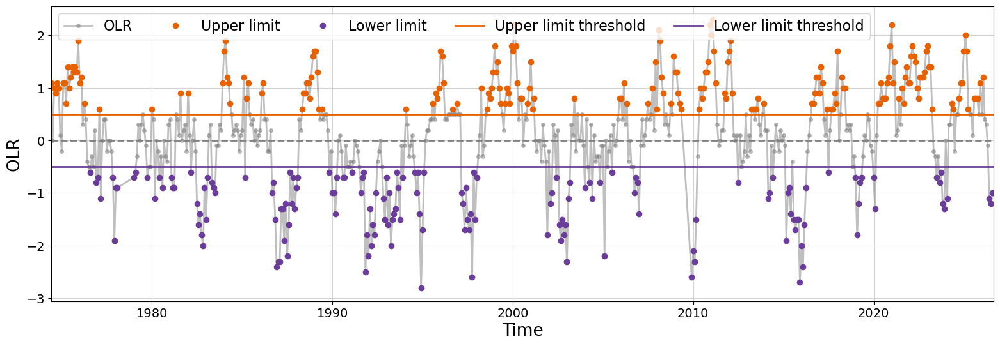

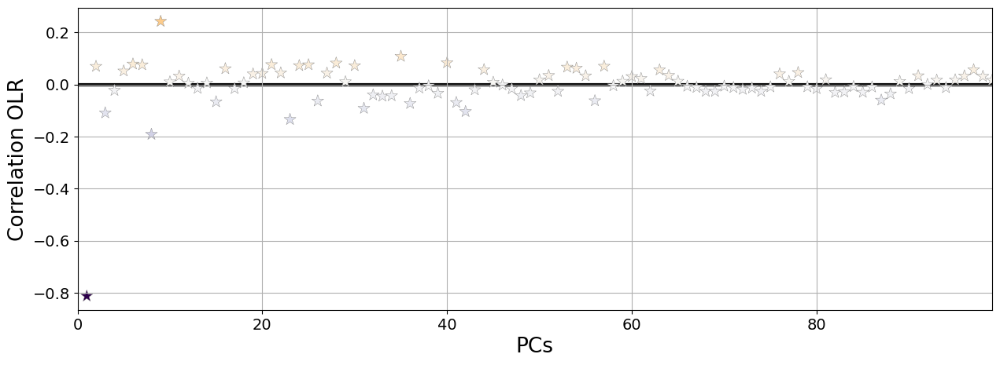

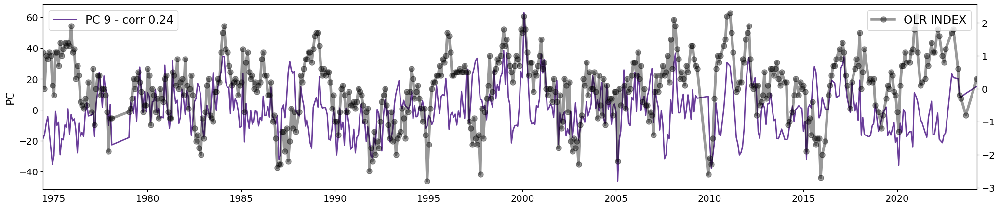

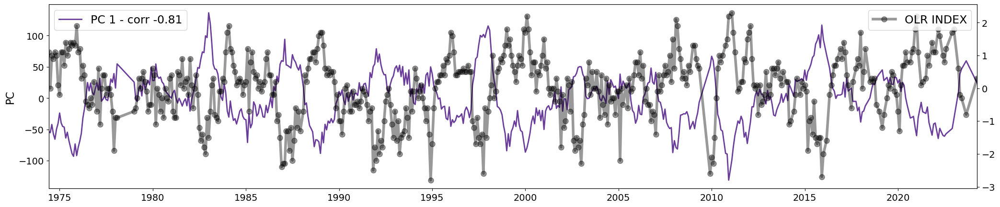

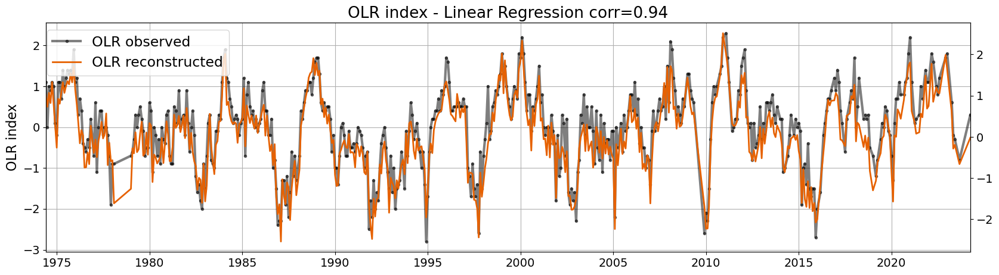

In [22]:
RESULTS['OLR'] = analyze_index('OLR', pcs, p_indices, detrend_deg=DETREND_DEG)

## PDO
**Pacific Decadal Oscillation** (NOAA NCEI, ERSSTv5): leading pattern of North Pacific (north of 20°N) SST variability, with ENSO-like structure but decadal persistence.

Multiple R  = 0.920
R^2         = 0.847
Intercept   = -0.423


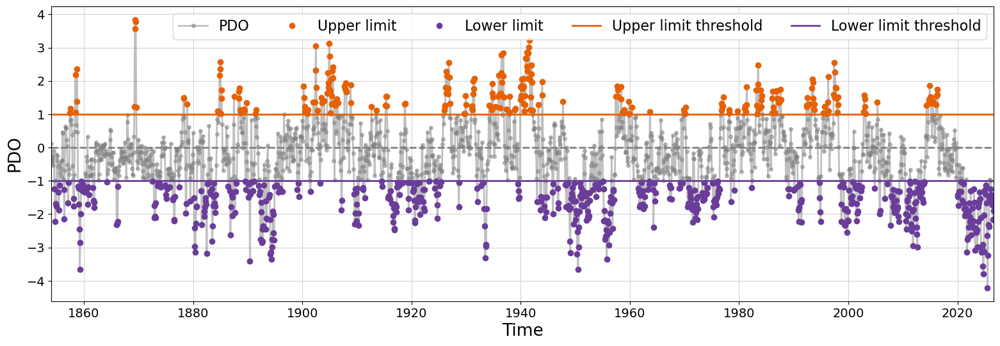

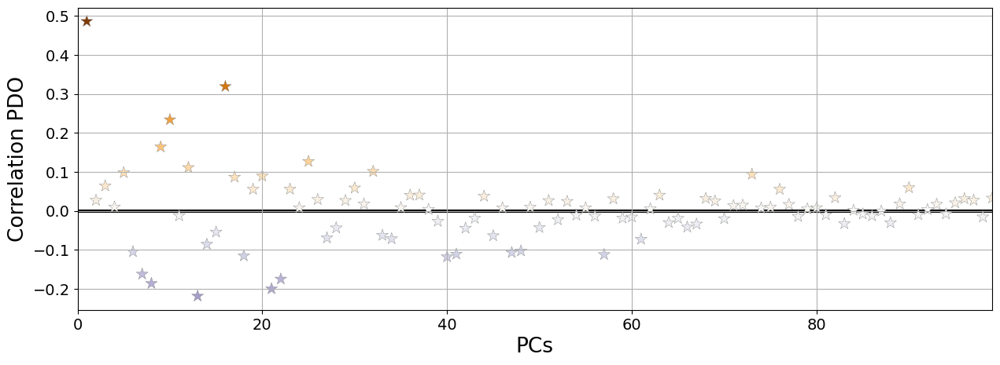

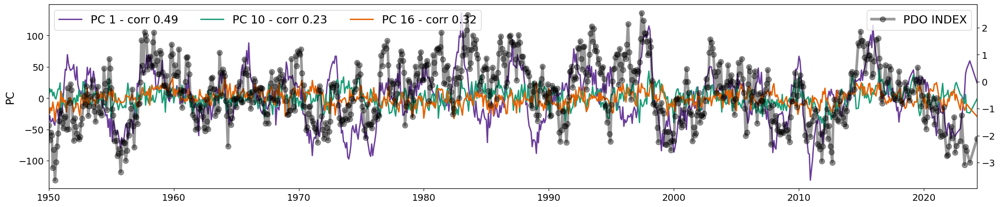

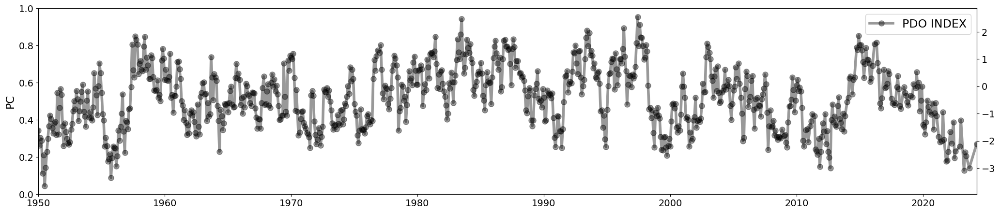

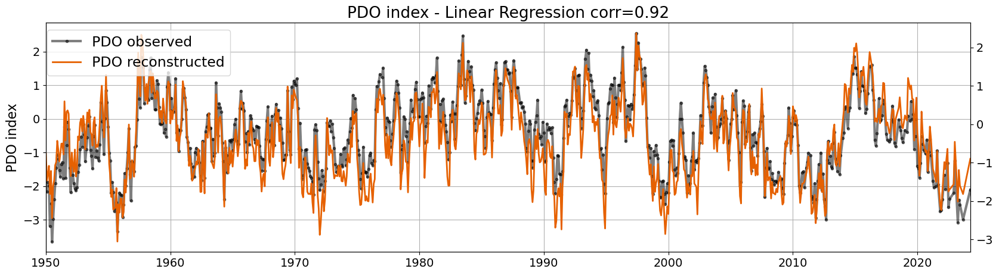

In [23]:
RESULTS['PDO'] = analyze_index('PDO', pcs, p_indices, detrend_deg=DETREND_DEG)

## SOI
**Southern Oscillation Index** (NOAA CPC, standardized): pressure difference between Tahiti and Darwin. Atmospheric component of ENSO (negative = El Niño).

Multiple R  = 0.941
R^2         = 0.885
Intercept   = 0.150


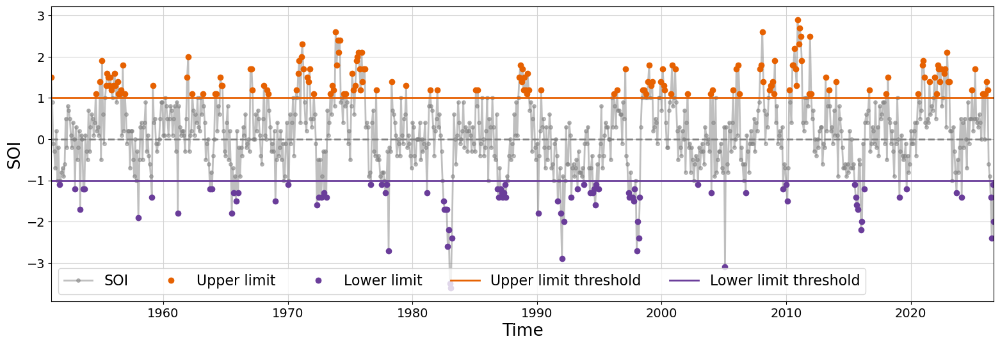

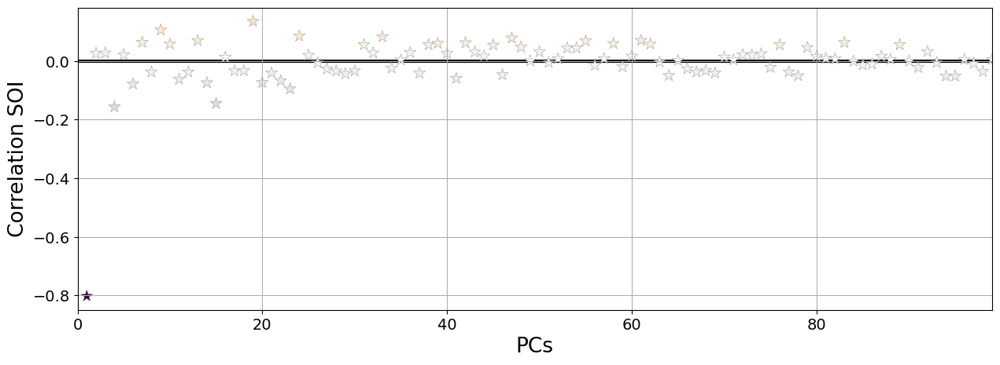

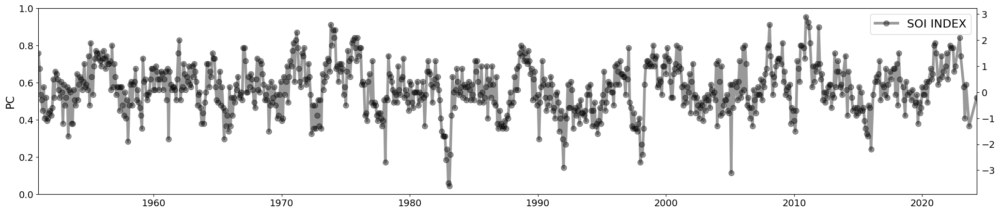

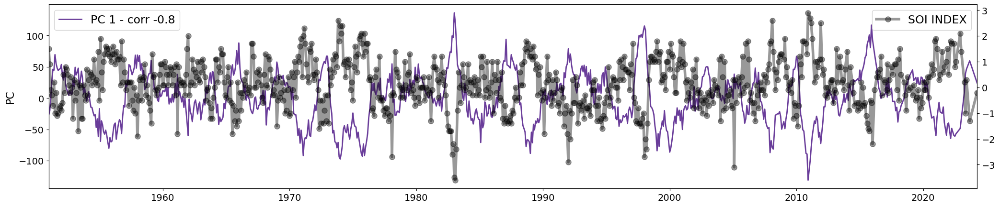

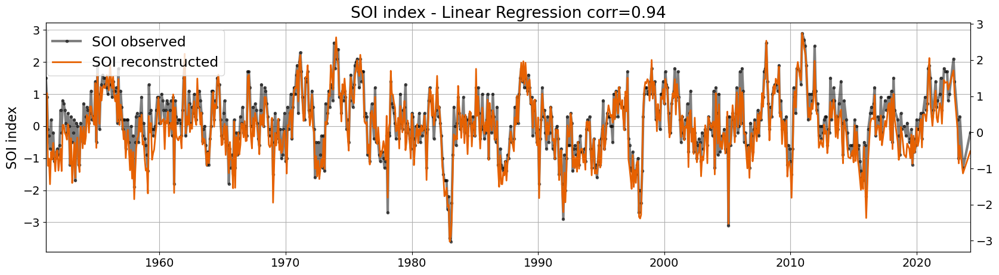

In [24]:
RESULTS['SOI'] = analyze_index('SOI', pcs, p_indices, detrend_deg=DETREND_DEG)

## PNA
**Pacific/North American pattern** (NOAA CPC): wave train from the North Pacific to North America that modulates winter temperature and precipitation over North America; partly forced by ENSO.

Multiple R  = 0.764
R^2         = 0.584
Intercept   = 0.043


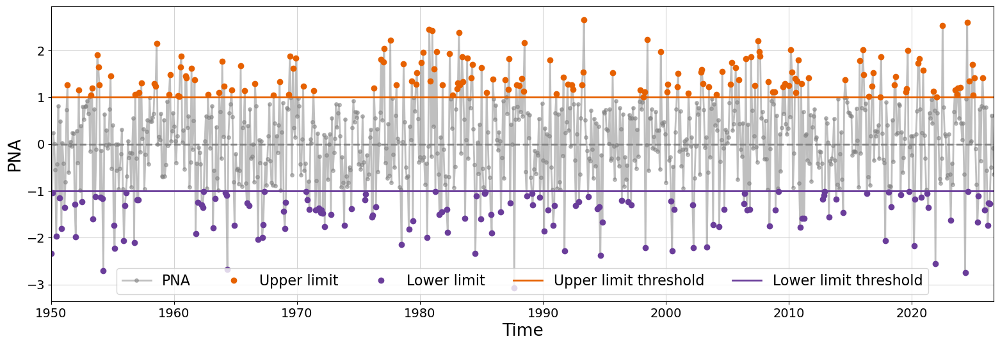

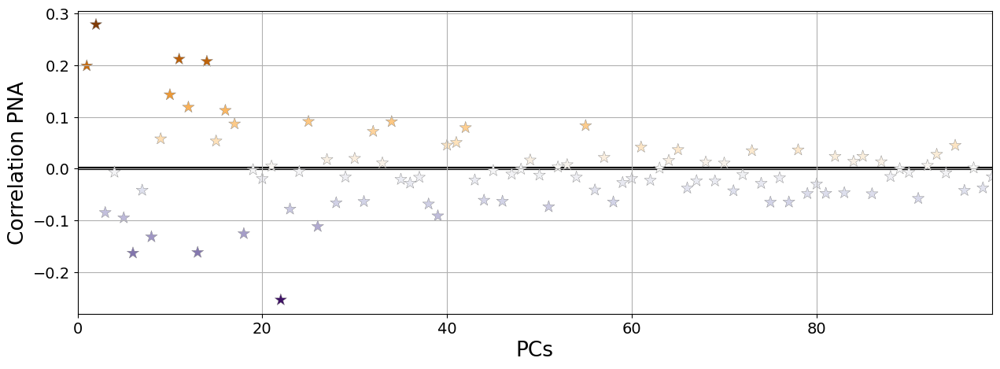

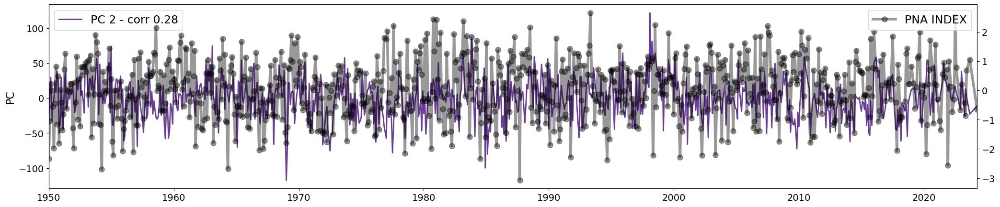

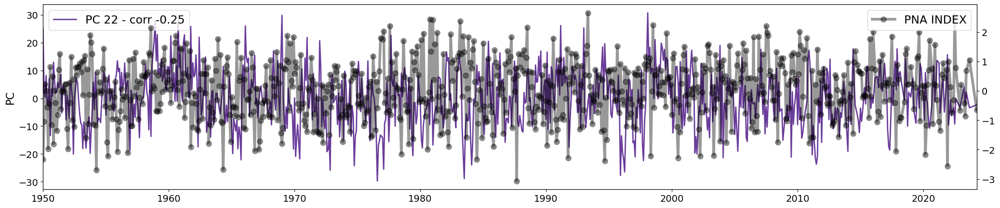

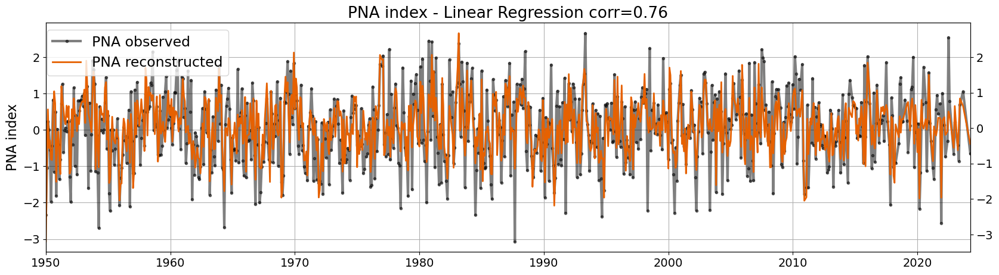

In [25]:
RESULTS['PNA'] = analyze_index('PNA', pcs, p_indices, detrend_deg=DETREND_DEG)

## SAM
**Southern Annular Mode** (Marshall, BAS, station-based): zonal pressure difference between 40°S and 65°S, i.e. the strength and position of the Southern Hemisphere westerlies. The available series ends in 2020.

Multiple R  = 0.907
R^2         = 0.823
Intercept   = 0.079


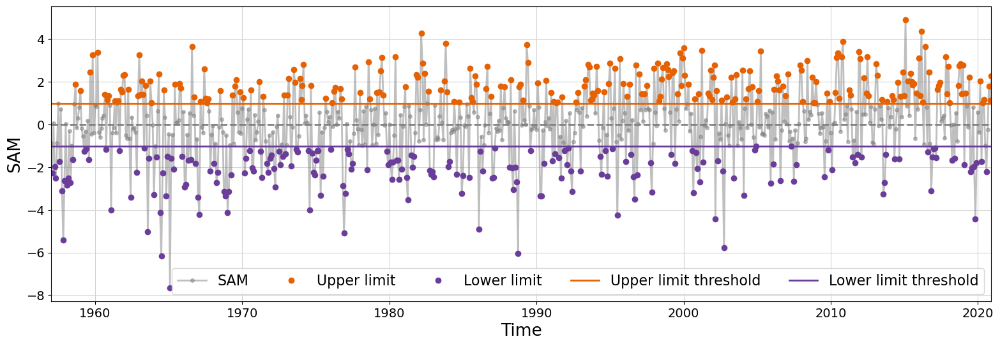

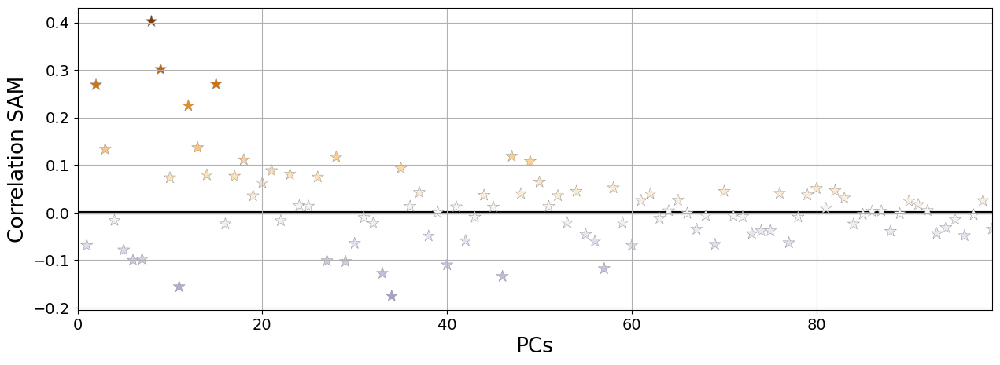

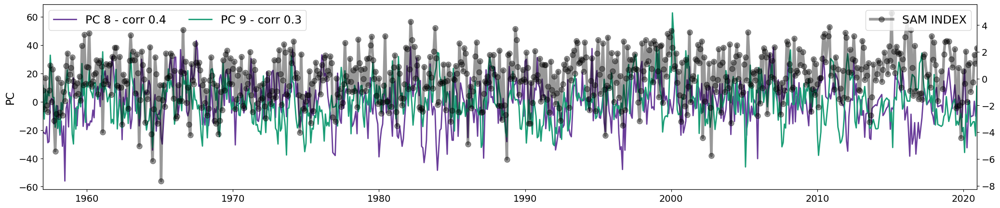

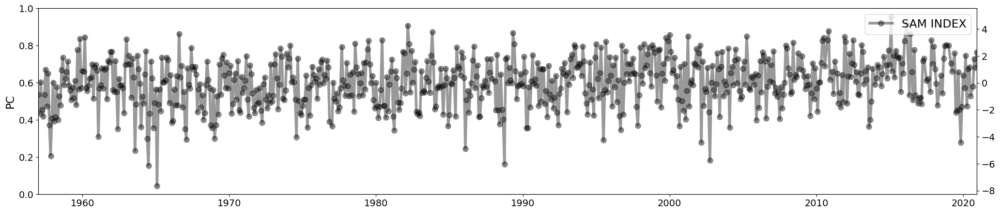

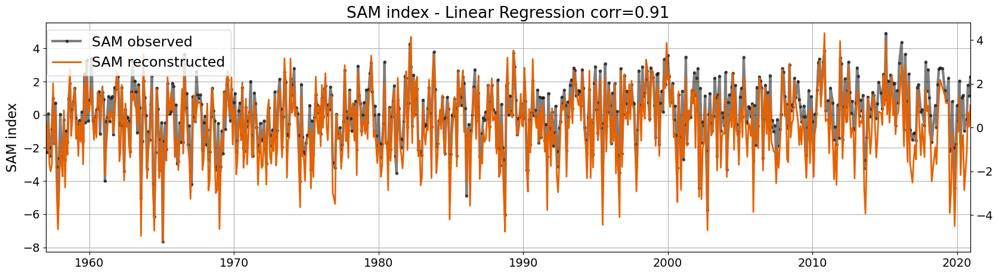

In [26]:
RESULTS['SAM'] = analyze_index('SAM', pcs, p_indices, detrend_deg=DETREND_DEG)

# **Climate indices summary**
## Multiple linear regression
Correlation between each observed index and its reconstruction from all the 100 PCs (in-sample), one
marker per index: how much of each index can be explained by the SST + MSL modes.

The PCs, the indices, these correlations and the explained variance of the PCA are saved to `outputs/`
for `02_PCs_analysis.ipynb`.

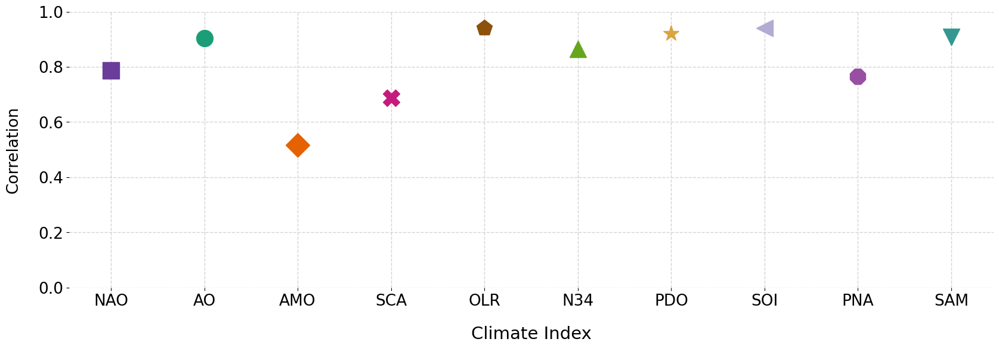

In [27]:
pcs_indices = save_pcs_indices(RESULTS, p_pcs_indices,
                               explained_variance_ratio=pca.explained_variance_ratio)
plot_regression_summary({name: r['corr_regression'] for name, r in RESULTS.items()});

## Correlation between indices and PCs
Heatmap: correlation of each index (rows) with each of the first 30 PCs (columns); orange: positive,
purple: negative. A single strong cell means the index is captured by one PC; many weak cells mean it is
spread over several PCs.

Table: the three PCs most correlated with each index (absolute value, with the sign of the correlation).

,#1,#2,#3
NAO,PC14 (+0.35),PC11 (-0.23),PC6 (+0.22)
AO,PC6 (+0.33),PC11 (-0.32),PC4 (-0.25)
AMO,PC3 (-0.22),PC6 (-0.19),PC7 (+0.17)
SCA,PC2 (-0.24),PC68 (-0.17),PC3 (-0.13)
OLR,PC1 (-0.81),PC9 (+0.24),PC8 (-0.19)
N34,PC1 (+0.81),PC21 (-0.09),PC3 (-0.09)
PDO,PC1 (+0.49),PC16 (+0.32),PC10 (+0.23)
SOI,PC1 (-0.80),PC4 (-0.16),PC15 (-0.14)
PNA,PC2 (+0.28),PC22 (-0.25),PC11 (+0.21)
SAM,PC8 (+0.40),PC9 (+0.30),PC15 (+0.27)


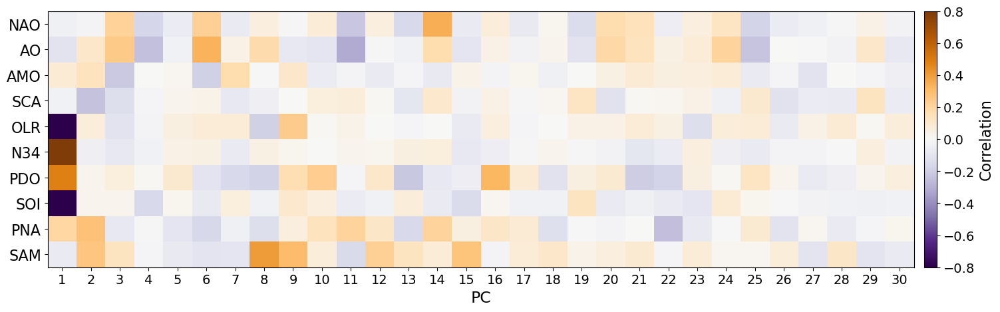

In [28]:
plot_pc_index_heatmap(pc_index_correlation(pcs_indices, n_pcs=30));
top_pcs_table(pcs_indices, n_pcs=n_pcs, k=3)

## Indices vs PCs
Each grey marker is the correlation of one index (marker shape) with one PC (x axis). For each PC, the
index with the highest correlation is highlighted in colour, so the figure tells which index each PC is
most related to (and which PCs are not related to any index).
### Absolute
Index with the highest absolute correlation for each PC.

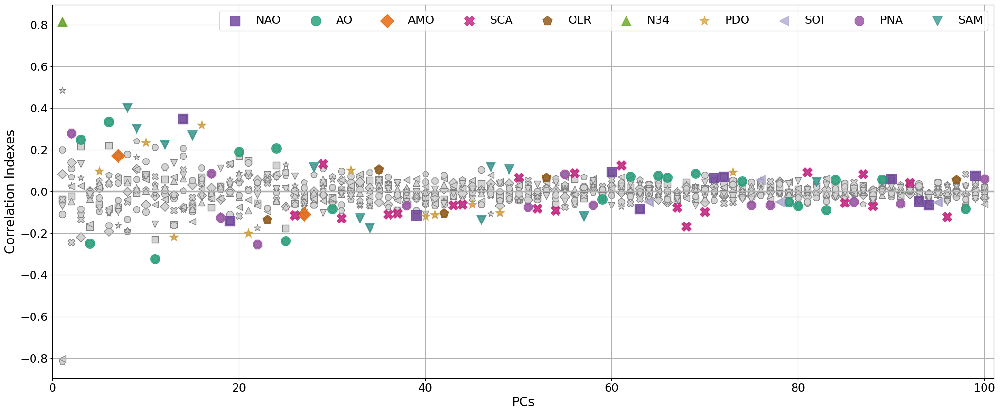

In [29]:
CORR = {name: r['corr'] for name, r in RESULTS.items()}
plot_correlation_summary(CORR, mode='abs');

### Positive + Negative
For each PC, the index with the highest positive correlation and the index with the most negative
correlation are highlighted (two per PC). First figure: all 100 PCs; second figure: zoom on the first 20.

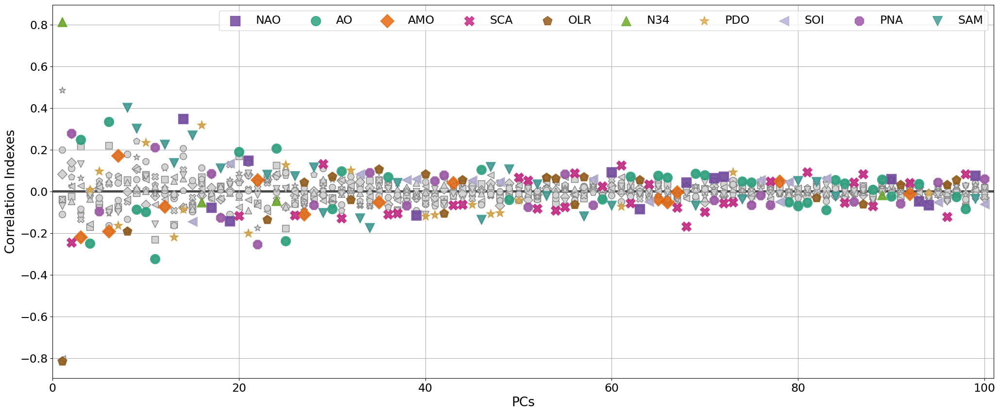

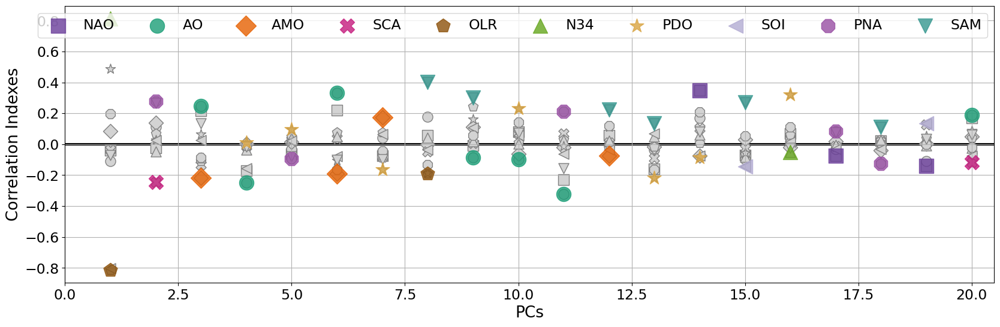

In [30]:
plot_correlation_summary(CORR, mode='both');
plot_correlation_summary(CORR, mode='both', xmax=20.5, figsize=(20, 6), s=(150, 300));